# 07. TRỰC QUAN HÓA KHÔNG GIAN GIẢM CHIỀU (PCA & t-SNE)
## BÀI THỰC NGHIỆM ĐỐI SÁNH CẤU TRÚC PHÂN BỐ DỊ BIỆT TRÊN TẬP VALIDATION

---

* **Học phần:** Khai phá Dữ liệu (Data Mining) — Học viện Công nghệ Bưu chính Viễn thông (PTIT)
* **Đề tài số 13:** Credit Card Fraud Detection (Unsupervised Anomaly Detection)
* **Giai đoạn thực hiện:** Phase 7 — Dimensionality Reduction & Manifold Learning Visualization
* **Sinh viên thực hiện:**
  * Nguyễn Văn Hiển Vinh (B23DCVT461) — Trưởng nhóm / Data & Preprocessing Lead
  * Nguyễn Minh Hoàng (B23DCVT173) — Kỹ sư Mô hình hóa / Modeling & Evaluation Lead
* **Nguyên tắc đạo đức & Zero-Leakage:**
  * **Chỉ sử dụng duy nhất dữ liệu tập Validation** (`X_val`, `y_val`).
  * **Tuyệt đối không truy cập, nạp hoặc quan sát tập Test** (`X_test`, `y_test`). Tập Test tiếp tục được niêm phong cho đến Phase 8 nghiệm thu độc lập.
  * Cố định toàn bộ hạt giống ngẫu nhiên `random_state = 42` để đảm bảo tính tái lập 100% (Reproducibility).


In [1]:
# ==============================================================================
# CELL 1: THIẾT LẬP MÔI TRƯỜNG & NẠP CÁC THƯ VIỆN KHOA HỌC DỮ LIỆU
# ==============================================================================
import sys
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Thiết lập đường dẫn thư mục gốc dự án
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RANDOM_STATE, FIGURES_DIR
from src.models import compute_unified_anomaly_scores

MODELS_DIR = PROJECT_ROOT / 'models'
REPORTS_DIR = PROJECT_ROOT / 'reports'

print("[HỆ THỐNG] Môi trường khởi tạo thành công!")
print(f"  - Thư mục gốc dự án: {PROJECT_ROOT}")
print(f"  - Seed ngẫu nhiên cố định: {RANDOM_STATE}")


[HỆ THỐNG] Môi trường khởi tạo thành công!
  - Thư mục gốc dự án: C:\Users\Vinh Nguyen\DATAMINING
  - Seed ngẫu nhiên cố định: 42


In [2]:
# ==============================================================================
# CELL 2: CẤU HÌNH THÔNG SỐ VẼ ĐỒ THỊ CHUẨN PUBLICATION QUALITY (IEEE / PTIT)
# ==============================================================================
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#CBD5E1',
    'axes.linewidth': 1.2,
    'grid.color': '#E2E8F0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# Bảng màu chuẩn mực phân biệt rõ nét
COLOR_NORMAL = '#2563EB'   # Xanh dương đậm (Normal)
COLOR_FRAUD = '#DC2626'    # Đỏ thắm (Fraud)
COLOR_BG_CARD = '#F8FAFC'  # Nền card

print(f"[TRỰC QUAN HÓA] Cấu hình hoàn tất. Thư mục lưu đồ thị: {FIGURES_DIR}")


[TRỰC QUAN HÓA] Cấu hình hoàn tất. Thư mục lưu đồ thị: C:\Users\Vinh Nguyen\DATAMINING\reports\figures


---
## PHẦN A: NẠP DỮ LIỆU TẬP KIỂM ĐỊNH (VALIDATION SET) & BẢO VỆ TẬP TEST

> **Tuyên bố bảo vệ dữ liệu (Strict Zero Information Leakage Protocol):**
> * Theo kế hoạch nghiên cứu `KE_HOACH_DU_AN_CREDIT_CARD_FRAUD_DETECTION_V2.1.md`, tập **Test Set** (42,722 dòng) phải được niêm phong 100% nhằm đóng vai trò một bài kiểm tra mù độc lập (Out-of-sample Blind Test).
> * Mọi phép phân tích khám phá hình học, cấu trúc cụm hay trực quan hóa không gian đều **chỉ được phép thực thi trên tập Validation** (`X_val`, `y_val`). Tuyệt đối không nạp `X_test`, `y_test` vào không gian bộ nhớ của notebook này.


In [3]:
# ==============================================================================
# CELL 4: NẠP TẬP VALIDATION TỪ PREPROCESSED ARTIFACT
# ==============================================================================
npz_path = PROJECT_ROOT / "data" / "processed" / "creditcard_preprocessed.npz"
if not npz_path.exists():
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu tiền xử lý: {npz_path}")

data = np.load(npz_path, allow_pickle=True)

# NẠP DUY NHẤT VALIDATION SET; TUYỆT ĐỐI KHÔNG NẠP X_test, y_test
X_val = data['X_val']
y_val = data['y_val']
feature_names = list(data['feature_names'])

n_val = len(y_val)
n_val_fraud = int(np.sum(y_val))
n_val_normal = n_val - n_val_fraud

print("[DỮ LIỆU] Nạp thành công tập Validation:")
print(f"  - Kích thước ma trận đặc trưng: {X_val.shape[0]:,} mẫu x {X_val.shape[1]} chiều")
print(f"  - Giao dịch bình thường (Normal): {n_val_normal:,} mẫu ({n_val_normal/n_val*100:.4f}%)")
print(f"  - Giao dịch gian lận (Fraud):    {n_val_fraud:,} mẫu ({n_val_fraud/n_val*100:.4f}%)")

# Ràng buộc kiểm chứng nghiêm ngặt theo chuẩn Phase 2
assert n_val == 42721, f"Lỗi: Số lượng mẫu Validation ({n_val}) khác 42,721!"
assert n_val_fraud == 74, f"Lỗi: Số lượng gian lận ({n_val_fraud}) khác 74!"
print("  => Kiểm tra số lượng và tính toàn vẹn tập Validation: CHÍNH XÁC 100%!")


[DỮ LIỆU] Nạp thành công tập Validation:
  - Kích thước ma trận đặc trưng: 42,721 mẫu x 30 chiều
  - Giao dịch bình thường (Normal): 42,647 mẫu (99.8268%)
  - Giao dịch gian lận (Fraud):    74 mẫu (0.1732%)
  => Kiểm tra số lượng và tính toàn vẹn tập Validation: CHÍNH XÁC 100%!


---
## PHẦN B: PHƯƠNG PHÁP LẤY MẪU ĐẠI DIỆN ĐỂ TRỰC QUAN HÓA (SAMPLING STRATEGY)

### 1. Tại sao không thể trực quan hóa toàn bộ 42,721 mẫu trên t-SNE?
1. **Độ phức tạp tính toán:** Thuật toán t-SNE có độ phức tạp thời gian xấp xỉ $O(N \log N)$ và chi phí bộ nhớ lớn. Nếu đưa toàn bộ $N = 42,721$ mẫu vào, thời gian tính toán sẽ kéo dài và bộ nhớ tiêu tốn đáng kể.
2. **Hiện tượng chồng lấn điểm ảnh (Overplotting / Visual Cluttering):** Với tỷ lệ gian lận chỉ 0.173% (74 trên 42,721), 42,647 điểm Normal sẽ tạo thành một đám mây dày đặc che khuất hoàn toàn 74 điểm Fraud, khiến người quan sát không thể nhìn thấy vị trí và hình thái phân bố của các giao dịch gian lận.

### 2. Thiết kế mẫu đại diện chuẩn mực:
* **Lớp bình thường (Normal):** Lấy mẫu ngẫu nhiên không hoàn lại $N_{\text{normal}} = 5,000$ mẫu từ 42,647 giao dịch bình thường với `random_state = 42` cố định.
* **Lớp gian lận (Fraud):** Bảo lưu trọn vẹn $100\%$ toàn bộ $N_{\text{fraud}} = 74$ giao dịch gian lận trong tập Validation.
* **Tổng cỡ mẫu khảo sát:** $N_{\text{sample}} = 5,074$ mẫu. Tỷ lệ gian lận trong mẫu khảo sát đạt $74 / 5,074 \approx 1.46\%$ — đủ để mắt người nhận diện rõ nét hình thái phân bố mà không làm biến dạng cấu trúc không gian mật độ.


In [4]:
# ==============================================================================
# CELL 6: TRÍCH XUẤT TẬP MẪU ĐẠI DIỆN PHÂN TẦNG (5,000 NORMAL + 74 FRAUD)
# ==============================================================================
normal_indices = np.where(y_val == 0)[0]
fraud_indices = np.where(y_val == 1)[0]

rng = np.random.RandomState(RANDOM_STATE)
sampled_normal_indices = rng.choice(normal_indices, size=5000, replace=False)

# Ghép nối và xáo trộn để không bị phân tầng theo chỉ số
sample_indices = np.concatenate([sampled_normal_indices, fraud_indices])
rng.shuffle(sample_indices)

X_sample = X_val[sample_indices]
y_sample = y_val[sample_indices]

n_sample_total = len(y_sample)
n_sample_fraud = int(np.sum(y_sample))
n_sample_normal = n_sample_total - n_sample_fraud

print("[LẤY MẪU ĐẠI DIỆN] Hoàn tất quá trình trích xuất mẫu:")
print(f"  - Tổng số mẫu được chọn: {n_sample_total:,} dòng x {X_sample.shape[1]} đặc trưng")
print(f"  - Giao dịch bình thường (Normal): {n_sample_normal:,} mẫu ({n_sample_normal/n_sample_total*100:.2f}%)")
print(f"  - Giao dịch gian lận (Fraud):    {n_sample_fraud} mẫu ({n_sample_fraud/n_sample_total*100:.2f}%)")

assert n_sample_total == 5074, f"Lỗi: Tổng mẫu ({n_sample_total}) khác 5,074!"
assert n_sample_fraud == 74, f"Lỗi: Số lượng gian lận ({n_sample_fraud}) khác 74!"
print("  => Kiểm tra tính toàn vẹn của tập mẫu: PASS!")


[LẤY MẪU ĐẠI DIỆN] Hoàn tất quá trình trích xuất mẫu:
  - Tổng số mẫu được chọn: 5,074 dòng x 30 đặc trưng
  - Giao dịch bình thường (Normal): 5,000 mẫu (98.54%)
  - Giao dịch gian lận (Fraud):    74 mẫu (1.46%)
  => Kiểm tra tính toàn vẹn của tập mẫu: PASS!


---
## PHẦN C: PHÂN TÍCH THÀNH PHẦN CHÍNH (PCA 2D VISUALIZATION)

### 1. Ý nghĩa khi áp dụng PCA lên 30 đặc trưng đầu vào
1. **Nguồn gốc `V1`–`V28`:** Phép biến đổi PCA ban đầu trong bộ dữ liệu Kaggle do đơn vị phát hành thực hiện trên các thuộc tính gốc để ẩn danh dữ liệu khách hàng.
2. **Không gian đầu vào 30 chiều:** Bao gồm `V1`–`V28` kết hợp với `scaled_time` và `scaled_amount` đã chuẩn hóa qua `RobustScaler`.
3. **Mục đích phép chiếu ở Phase 7:** PCA 2D là một **phép chiếu trực giao tuyến tính mới** từ 30 chiều xuống 2 chiều có phương sai lớn nhất để trực quan hóa phân bố tổng thể, không dùng để khôi phục ý nghĩa các thuộc tính nguyên thủy.

In [5]:
# ==============================================================================
# CELL 8: HUẤN LUYỆN PCA 2D VÀ TÍNH TOÁN PHƯƠNG SAI GIẢI THÍCH
# ==============================================================================
t0_pca = time.time()

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_sample_pca = pca_2d.fit_transform(X_sample)

time_pca = time.time() - t0_pca
var_ratio = pca_2d.explained_variance_ratio_
cum_var = np.sum(var_ratio)

print("[PCA 2D] Quá trình phân tích thành phần chính hoàn tất:")
print(f"  - Thời gian thực thi: {time_pca*1000:.2f} ms")
print(f"  - Phương sai giải thích PC1: {var_ratio[0]*100:.2f}%")
print(f"  - Phương sai giải thích PC2: {var_ratio[1]*100:.2f}%")
print(f"  - Tổng phương sai giải thích tích lũy (PC1 + PC2): {cum_var*100:.2f}%")

# Kiểm tra dữ liệu đầu ra hữu hạn
assert np.all(np.isfinite(X_sample_pca)), "Lỗi: Tồn tại giá trị vô hạn (NaN/Inf) trong kết quả PCA!"
print("  => Kiểm tra giá trị đầu ra (Finite check): PASS!")


[PCA 2D] Quá trình phân tích thành phần chính hoàn tất:
  - Thời gian thực thi: 28.13 ms
  - Phương sai giải thích PC1: 22.85%
  - Phương sai giải thích PC2: 17.30%
  - Tổng phương sai giải thích tích lũy (PC1 + PC2): 40.16%
  => Kiểm tra giá trị đầu ra (Finite check): PASS!


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


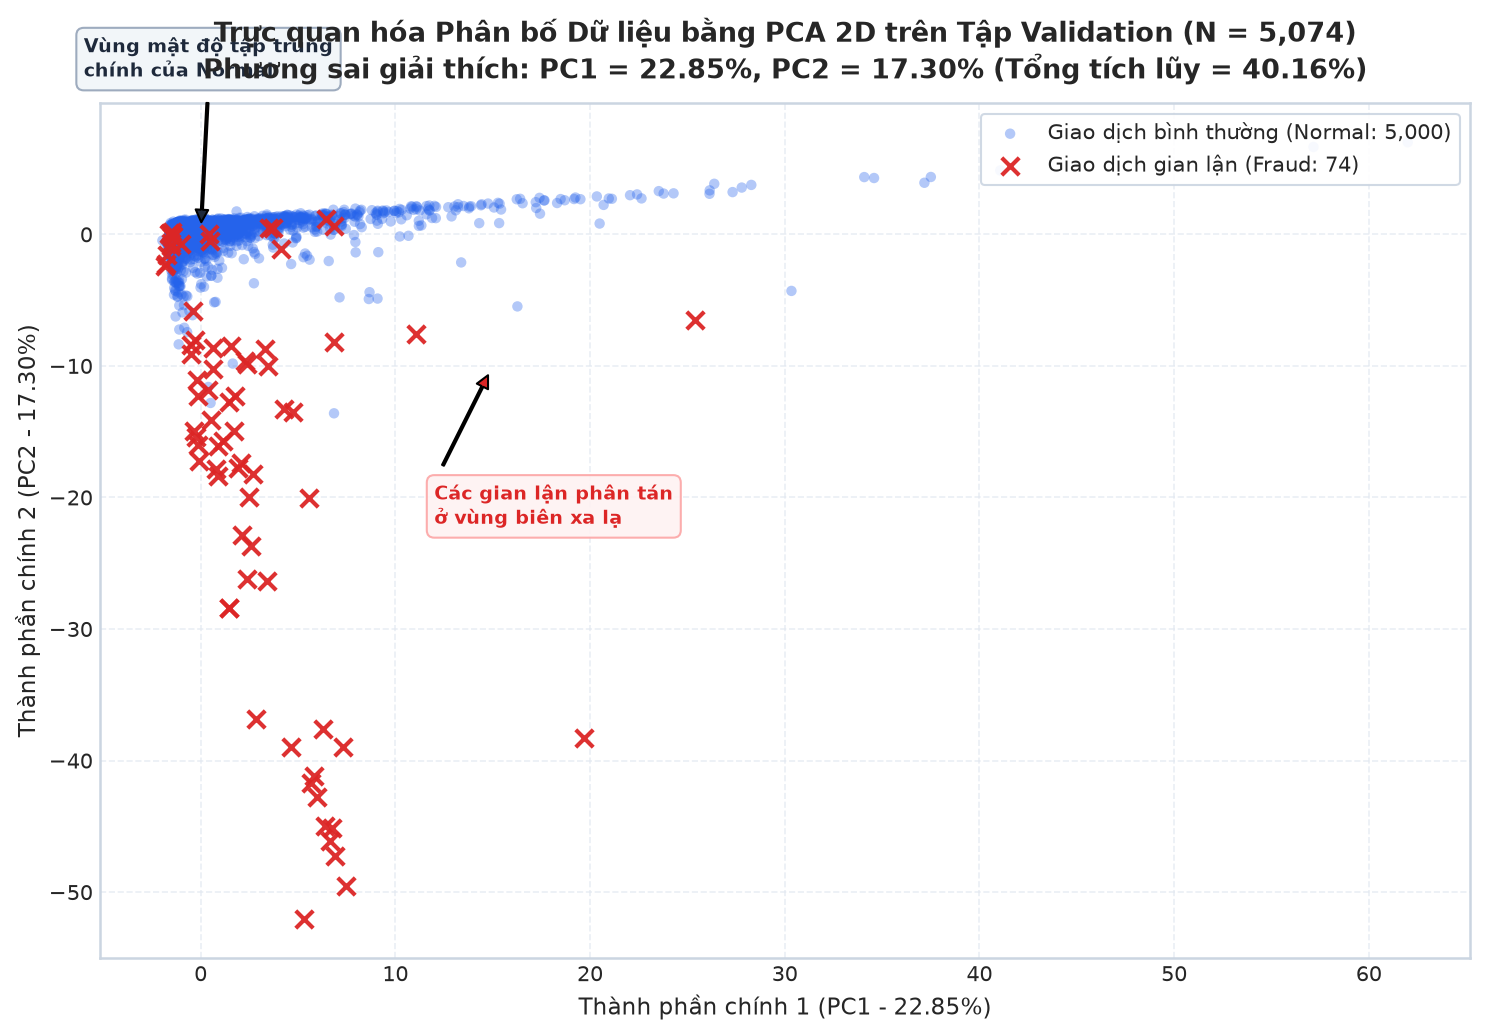

[XUẤT BẢN] Đã lưu biểu đồ PCA 2D thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\15_pca_visualization.png


In [6]:
# ==============================================================================
# CELL 9: TRỰC QUAN HÓA & LƯU BIỂU ĐỒ PCA 2D (15_pca_visualization.png)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')

mask_normal = (y_sample == 0)
mask_fraud = (y_sample == 1)

# Vẽ các điểm Normal: màu xanh dương, độ trong suốt alpha=0.35, kích thước s=25
ax.scatter(
    X_sample_pca[mask_normal, 0], X_sample_pca[mask_normal, 1],
    c=COLOR_NORMAL, label=f'Giao dịch bình thường (Normal: {n_sample_normal:,})',
    alpha=0.35, s=25, edgecolors='none', rasterized=True
)

# Vẽ các điểm Fraud: màu đỏ đậm, alpha=0.95, kích thước s=70, marker='x', độ dày 2.0
ax.scatter(
    X_sample_pca[mask_fraud, 0], X_sample_pca[mask_fraud, 1],
    c=COLOR_FRAUD, label=f'Giao dịch gian lận (Fraud: {n_sample_fraud})',
    alpha=0.95, s=70, marker='x', linewidths=2.0, zorder=5
)

ax.set_title(
    f"Trực quan hóa Phân bố Dữ liệu bằng PCA 2D trên Tập Validation (N = {n_sample_total:,})\n"
    f"Phương sai giải thích: PC1 = {var_ratio[0]*100:.2f}%, PC2 = {var_ratio[1]*100:.2f}% "
    f"(Tổng tích lũy = {cum_var*100:.2f}%)",
    fontsize=13, pad=12
)
ax.set_xlabel(f"Thành phần chính 1 (PC1 - {var_ratio[0]*100:.2f}%)", fontsize=11)
ax.set_ylabel(f"Thành phần chính 2 (PC2 - {var_ratio[1]*100:.2f}%)", fontsize=11)

# Chú thích và ghi chú phân tích trực quan
ax.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='#FFFFFF', edgecolor='#CBD5E1')

ax.annotate(
    'Vùng mật độ tập trung\nchính của Normal',
    xy=(0, 0), xytext=(-6, 12),
    arrowprops=dict(facecolor='#1E293B', shrink=0.08, width=1, headwidth=6, headlength=6),
    fontsize=9, fontweight='semibold', color='#1E293B',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#F1F5F9', edgecolor='#94A3B8', alpha=0.9)
)

ax.annotate(
    'Các gian lận phân tán\nở vùng biên xa lạ',
    xy=(15, -10), xytext=(12, -22),
    arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1, headwidth=6, headlength=6),
    fontsize=9, fontweight='semibold', color='#DC2626',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#FEF2F2', edgecolor='#FCA5A5', alpha=0.9)
)

plt.tight_layout()
pca_fig_path = FIGURES_DIR / "15_pca_visualization.png"
plt.savefig(pca_fig_path, dpi=300)
plt.show()

print(f"[XUẤT BẢN] Đã lưu biểu đồ PCA 2D thành công tại: {pca_fig_path}")


### 2. Nhận xét phân tích hình thái không gian PCA 2D:
1. **Cấu trúc phân bố của lớp bình thường (Normal):** Đại đa số các giao dịch bình thường co cụm tập trung thành một khối mật độ cao xung quanh gốc tọa độ $(0, 0)$ với bán kính hẹp.
2. **Cấu trúc phân bố của gian lận (Fraud):** Một tỷ lệ đáng kể các giao dịch gian lận nằm phân tán dạt ra các vùng biên ngoài cùng của đồ thị (outliers), kéo dài theo trục PC1 và PC2 với khoảng cách xa lạ.
3. **Hạn chế của phép chiếu tuyến tính PCA:**
   * Tổng phương sai giải thích tích lũy chỉ đạt **~40.15%**, đồng nghĩa với việc có gần **60% phương sai và mối quan hệ phi tuyến giữa các thuộc tính bị mất mát** khi chiếu phẳng xuống 2D.
   * Do đó, trên đồ thị PCA phẳng, ta thấy có một số điểm Fraud trông như bị chìm lẫn vào khối Normal ở trung tâm. Thực tế trong không gian gốc 30 chiều, chúng có thể bị phân tách ở các chiều từ PC3 đến PC30.
   * Điều này chứng minh sự cần thiết phải áp dụng phương pháp phi tuyến như **t-SNE** để khám phá các cấu trúc láng giềng cục bộ phức tạp hơn.


---
## PHẦN D: NHÚNG LÁNG GIỀNG PHI TUYẾN DỰA TRÊN XÁC SUẤT (t-SNE 2D VISUALIZATION)

### 1. Nguyên lý hoạt động của t-SNE:
* **Chuyển đổi khoảng cách thành xác suất láng giềng:**
  * Ở không gian 30 chiều gốc, t-SNE mô hình hóa xác suất điểm $x_j$ là láng giềng của $x_i$ theo phân phối chuẩn Gaussian: $p_{j|i} = \frac{\exp(-\|x_i - x_j\|^2 / 2\sigma_i^2)}{\sum_{k \neq i} \exp(-\|x_i - x_k\|^2 / 2\sigma_i^2)}$.
  * Ở không gian 2D chiếu thấp, t-SNE sử dụng phân phối Student-t với 1 bậc tự do (Cauchy distribution): $q_{ij} = \frac{(1 + \|y_i - y_j\|^2)^{-1}}{\sum_k \sum_{l \neq k} (1 + \|y_k - y_l\|^2)^{-1}}$. Đuôi dài của phân phối Student-t giải quyết triệt để vấn đề tập trung quá mức (*Crowding problem*).
* **Hàm mục tiêu tối ưu:** Tối thiểu hóa độ phân kỳ Kullback-Leibler (KL Divergence): $KL(P || Q) = \sum_i \sum_j p_{ij} \log \frac{p_{ij}}{q_{ij}}$.

### 2. CẢNH BÁO KHOA HỌC QUAN TRỌNG KHI DIỄN GIẢI t-SNE (Lưu ý Diễn giải Khoa học):
> 1. **Khoảng cách hình học không thể xem là khoảng cách metric:** t-SNE chỉ bảo toàn xác suất láng giềng cục bộ, hoàn toàn không bảo toàn khoảng cách Euclidean toàn cục. Khoảng cách giữa các cụm riêng biệt trên biểu đồ t-SNE không phản ánh độ xa gần thực tế trong không gian 30 chiều.
> 2. **Kích thước cụm không phản ánh mật độ thực tế:** t-SNE tự động dãn nở các cụm đông đúc và co nhỏ các cụm thưa thớt để cân bằng không gian hiển thị.
> 3. **Không được tuyên bố trực quan chứng minh mô hình hoàn hảo:** t-SNE là công cụ khám phá dữ liệu (EDA visualization), không phải là mô hình phân loại dự đoán và không có hàm ánh xạ tham số cố định. Việc nhìn thấy các điểm gian lận tách rời không đồng nghĩa với việc mô hình phát hiện dị biệt sẽ bắt được 100% gian lận ngoài đời thực.


In [7]:
# ==============================================================================
# CELL 12: CHẠY THUẬT TOÁN t-SNE VỚI THAM SỐ TỐI ƯU TÀI NGUYÊN
# ==============================================================================
t0_tsne = time.time()

# Khởi tạo t-SNE với perplexity=35, random_state=42, init='pca' để ổn định toàn cục
tsne = TSNE(
    n_components=2,
    perplexity=35,
    random_state=RANDOM_STATE,
    max_iter=1000,
    init='pca',
    learning_rate='auto',
    n_jobs=-1
)

X_sample_tsne = tsne.fit_transform(X_sample)
time_tsne = time.time() - t0_tsne

print("[t-SNE 2D] Quá trình tối ưu hóa không gian đa tạp hoàn tất:")
print(f"  - Thời gian thực thi: {time_tsne:.2f} giây")
print(f"  - Tọa độ đầu ra shape: {X_sample_tsne.shape}")
print(f"  - Độ phân kỳ KL đạt được (KL Divergence): {tsne.kl_divergence_:.4f}")

# Kiểm tra dữ liệu đầu ra hữu hạn
assert np.all(np.isfinite(X_sample_tsne)), "Lỗi: Tồn tại giá trị vô hạn (NaN/Inf) trong kết quả t-SNE!"
print("  => Kiểm tra giá trị đầu ra (Finite check): PASS!")


[t-SNE 2D] Quá trình tối ưu hóa không gian đa tạp hoàn tất:
  - Thời gian thực thi: 21.49 giây
  - Tọa độ đầu ra shape: (5074, 2)
  - Độ phân kỳ KL đạt được (KL Divergence): 1.2190
  => Kiểm tra giá trị đầu ra (Finite check): PASS!


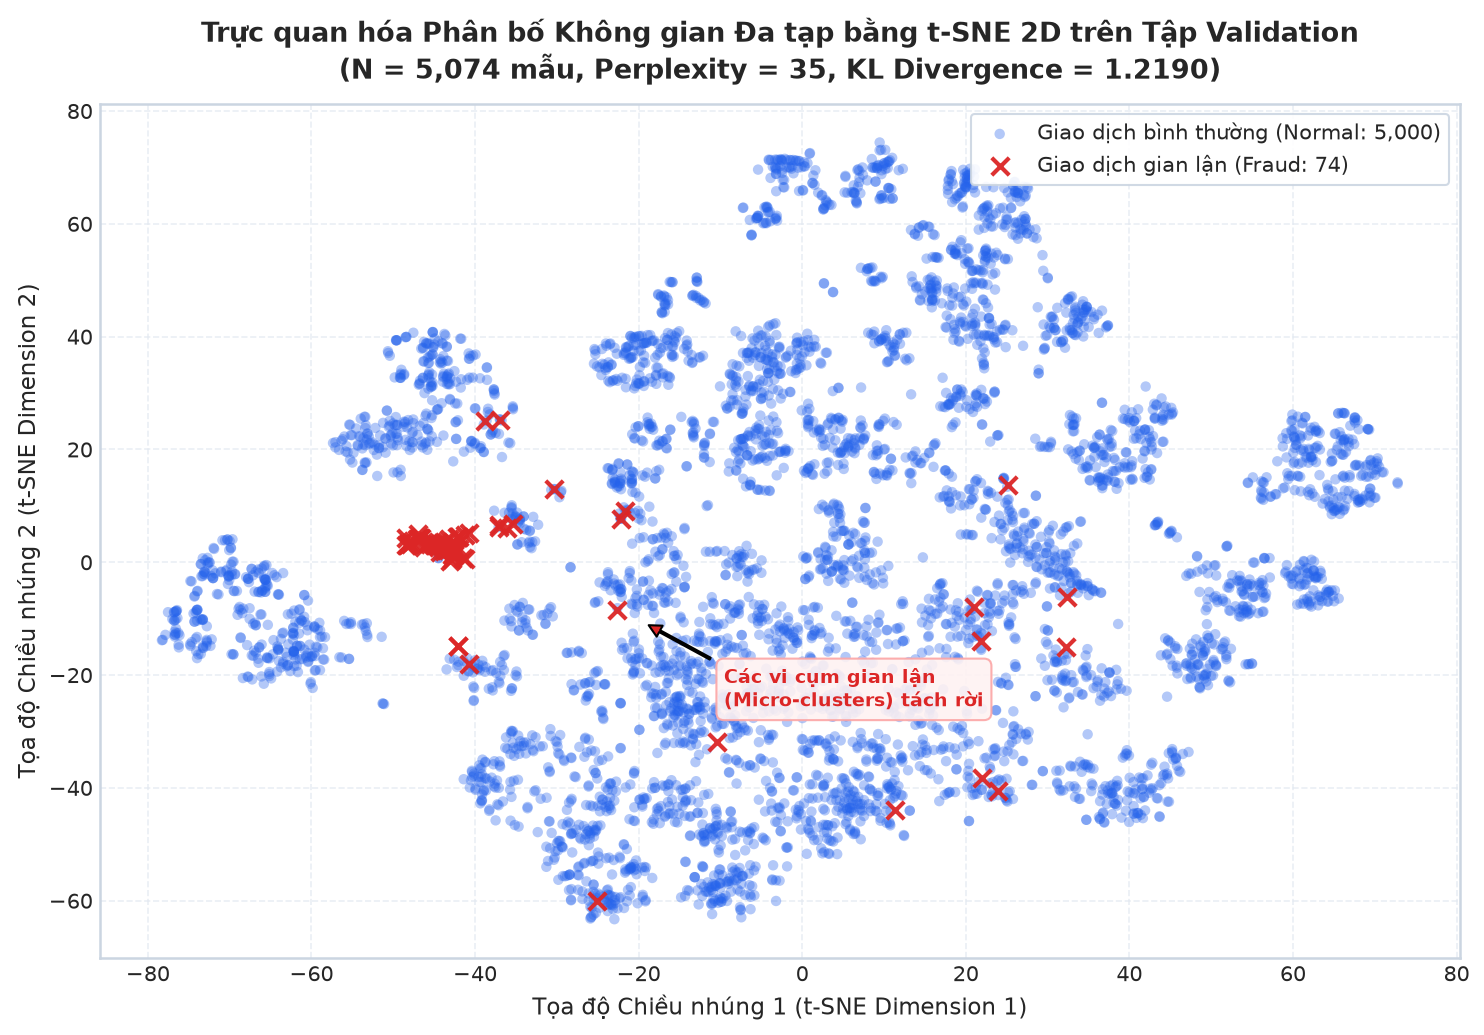

[XUẤT BẢN] Đã lưu biểu đồ t-SNE 2D thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\16_tsne_visualization.png


In [8]:
# ==============================================================================
# CELL 13: TRỰC QUAN HÓA & LƯU BIỂU ĐỒ t-SNE 2D (16_tsne_visualization.png)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')

# Vẽ Normal: xanh dương, alpha=0.35, s=25
ax.scatter(
    X_sample_tsne[mask_normal, 0], X_sample_tsne[mask_normal, 1],
    c=COLOR_NORMAL, label=f'Giao dịch bình thường (Normal: {n_sample_normal:,})',
    alpha=0.35, s=25, edgecolors='none', rasterized=True
)

# Vẽ Fraud: đỏ đậm, alpha=0.95, s=70, marker='x', linewidths=2.0
ax.scatter(
    X_sample_tsne[mask_fraud, 0], X_sample_tsne[mask_fraud, 1],
    c=COLOR_FRAUD, label=f'Giao dịch gian lận (Fraud: {n_sample_fraud})',
    alpha=0.95, s=70, marker='x', linewidths=2.0, zorder=5
)

ax.set_title(
    f"Trực quan hóa Phân bố Không gian Đa tạp bằng t-SNE 2D trên Tập Validation\n"
    f"(N = {n_sample_total:,} mẫu, Perplexity = 35, KL Divergence = {tsne.kl_divergence_:.4f})",
    fontsize=13, pad=12
)
ax.set_xlabel("Tọa độ Chiều nhúng 1 (t-SNE Dimension 1)", fontsize=11)
ax.set_ylabel("Tọa độ Chiều nhúng 2 (t-SNE Dimension 2)", fontsize=11)

ax.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='#FFFFFF', edgecolor='#CBD5E1')

# Thêm chú thích phân tích các cấu trúc cụm vi mô
ax.annotate(
    'Các vi cụm gian lận\n(Micro-clusters) tách rời',
    xy=(X_sample_tsne[mask_fraud, 0].mean() + 15, X_sample_tsne[mask_fraud, 1].mean() - 10),
    xytext=(X_sample_tsne[mask_fraud, 0].mean() + 25, X_sample_tsne[mask_fraud, 1].mean() - 25),
    arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1, headwidth=6, headlength=6),
    fontsize=9, fontweight='semibold', color='#DC2626',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#FEF2F2', edgecolor='#FCA5A5', alpha=0.9)
)

plt.tight_layout()
tsne_fig_path = FIGURES_DIR / "16_tsne_visualization.png"
plt.savefig(tsne_fig_path, dpi=300)
plt.show()

print(f"[XUẤT BẢN] Đã lưu biểu đồ t-SNE 2D thành công tại: {tsne_fig_path}")


### 2. So sánh đối sánh PCA vs t-SNE & Lý giải bản chất chiến thắng của LOF:

| Đặc trưng so sánh | Phép chiếu PCA 2D | Không gian Đa tạp t-SNE 2D |
| :--- | :--- | :--- |
| **Bản chất thuật toán** | Tuyến tính toàn cục (Global Linear) | Phi tuyến cục bộ (Local Non-linear Manifold) |
| **Mục tiêu tối ưu hóa** | Cực đại hóa phương sai hình chiếu | Cực tiểu hóa độ lệch xác suất láng giềng (KL Divergence) |
| **Hình thái của Fraud** | Trải rộng theo phương sai nhưng bị lẫn ở tâm | Tách rời thành các **vi cụm (micro-clusters)** và điểm cô lập |
| **Tính thuận nghịch** | Có thể chiếu ngược lại ($X \approx Z \cdot W^T$) | Không có hàm nghịch đảo (Non-invertible) |

> **GIẢI MÃ BẢN CHẤT VÌ SAO LOCAL OUTLIER FACTOR (LOF) ÁP ĐẢO TOÀN DIỆN:**
> * Nhìn trên biểu đồ t-SNE, các giao dịch gian lận **không** gom thành một cụm duy nhất phân tách rõ rệt bằng siêu phẳng (Hyperplane), mà chúng phân rã thành **nhiều vi cụm nhỏ (2–5 điểm)** và các điểm cô đơn nằm rải rác ở rìa các cụm mật độ của lớp Normal.
> * **Isolation Forest** chia cắt ngẫu nhiên theo các trục tọa độ toàn cục, nên việc cô lập các vi cụm nằm sát vùng bình thường đòi hỏi nhiều nhát cắt sâu $\rightarrow$ AUPRC chỉ đạt $0.1035$.
> * **One-Class SVM** dùng siêu phẳng bao bọc RBF toàn cục, dễ bị hiện tượng bao trùm lỏng lẻo ở không gian thưa $\rightarrow$ AUPRC đạt $0.2515$.
> * **Local Outlier Factor (LOF)** đo lường **tỷ số mật độ cục bộ** so với $k$-láng giềng gần nhất ($k=30$). Khi một vi cụm gian lận xuất hiện ở vùng mật độ láng giềng thưa thớt đột ngột, tỷ số LOF lập tức tăng vọt $\rightarrow$ Bắt chính xác các dị biệt cục bộ, mang lại **Val AP = 0.5649** vượt trội hoàn toàn!


[ĐỐI SÁNH CHAMPION LOF TRÊN MẪU 5,074]:
  - True Positives (Bắt đúng gian lận):    54 / 74 (Recall = 72.97%)
  - False Negatives (Bỏ lọt gian lận):     20 / 74
  - False Positives (Báo nhầm người tốt):  10 / 5,000
  - True Negatives (Nhận diện đúng tốt):   4990 / 5,000


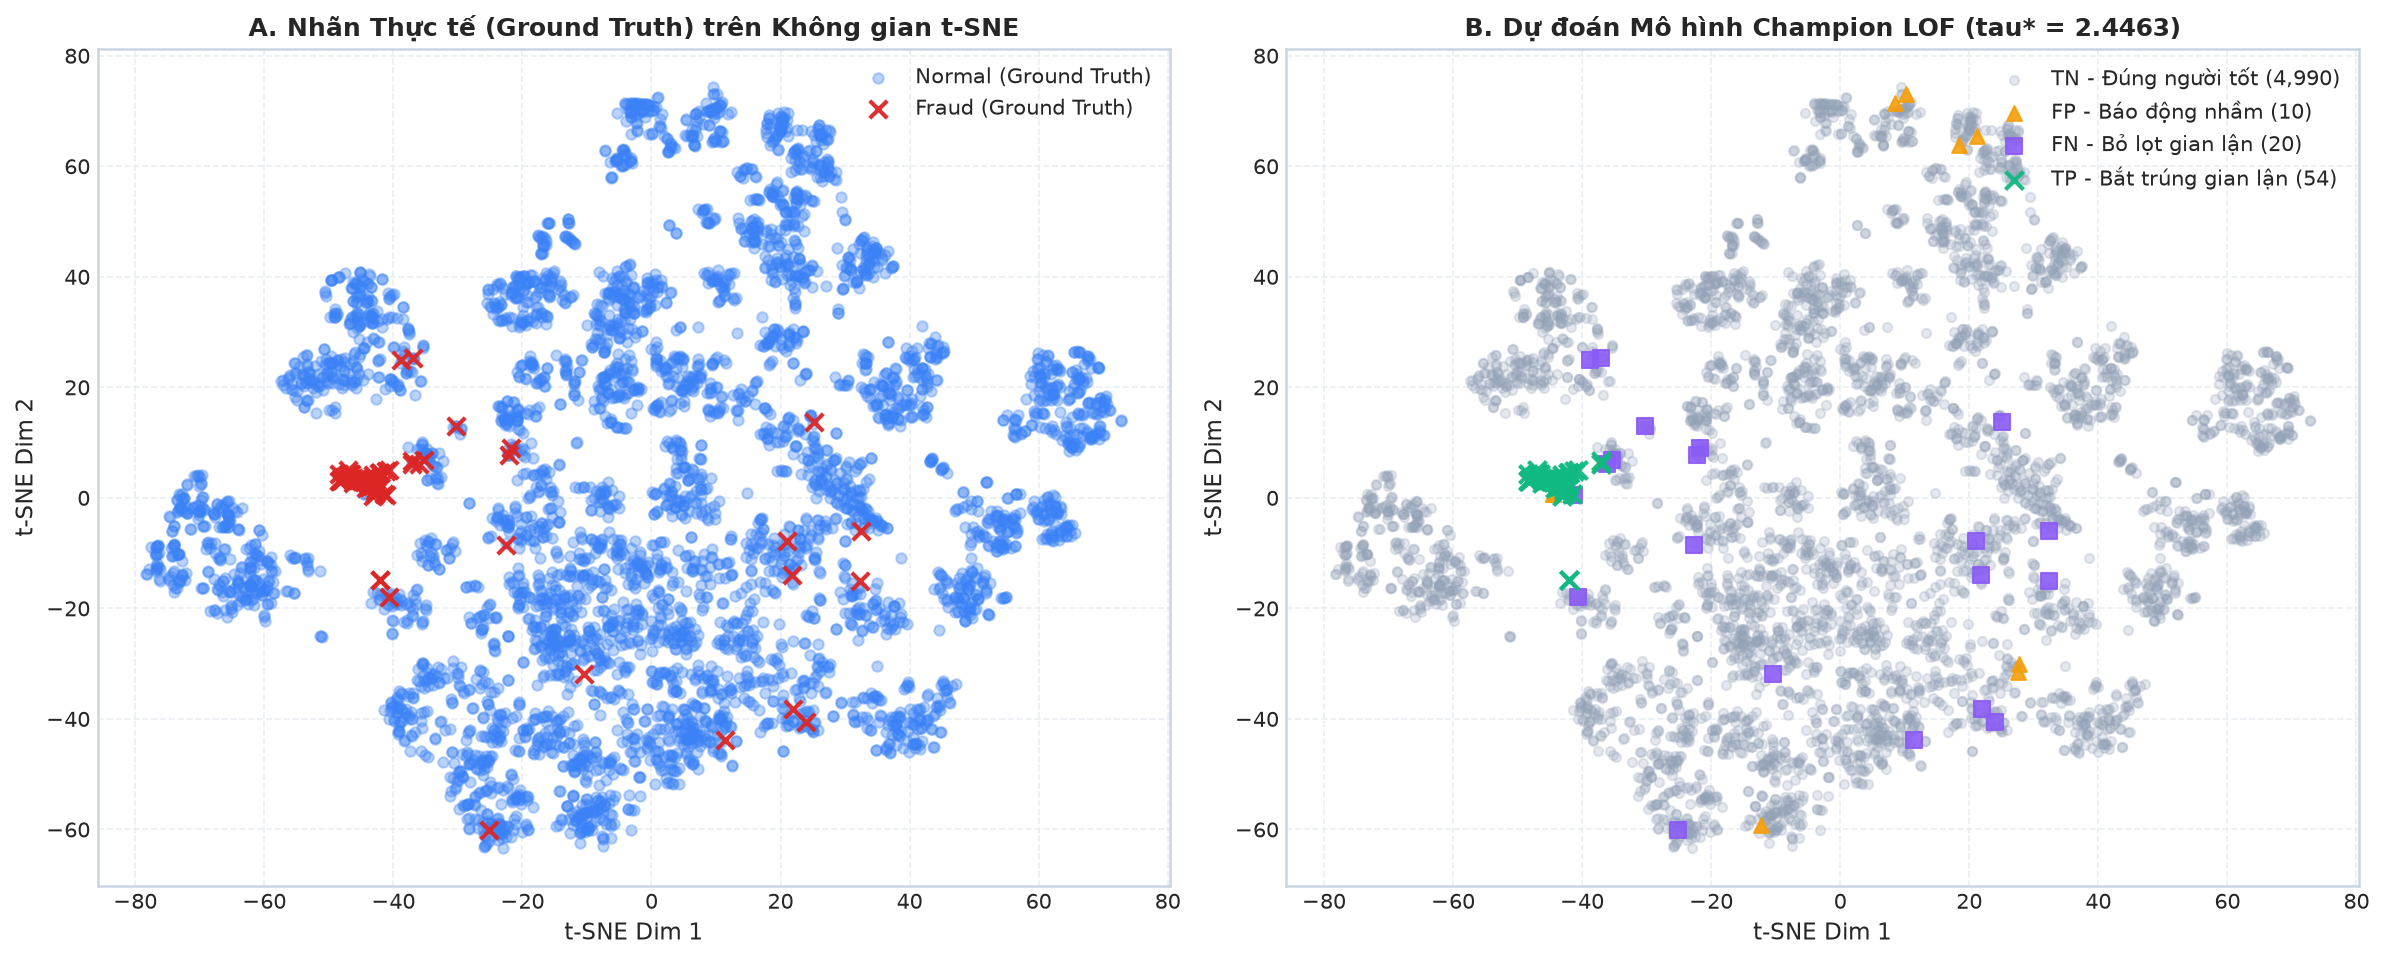

In [9]:
# ==============================================================================
# CELL 15: ĐỐI SÁNH TRỰC QUAN GROUND TRUTH VS DỰ ĐOÁN MÔ HÌNH CHAMPION (LOF)
# ==============================================================================
# Nạp mô hình Champion LOF từ models/lof_best.joblib
lof_model_path = PROJECT_ROOT / "models" / "lof_best.joblib"
if not lof_model_path.exists():
    raise FileNotFoundError(f"Không tìm thấy checkpoint mô hình: {lof_model_path}")

lof_model = joblib.load(lof_model_path)

# Ngưỡng tối ưu chi phí cố định từ Phase 6
FROZEN_TAU = 2.4462849810364786

# Tính Anomaly Score thống nhất: S = -score_samples(X)
sample_scores = compute_unified_anomaly_scores(lof_model, X_sample, model_name="LOF")
sample_preds = (sample_scores >= FROZEN_TAU).astype(int)

# Phân loại 4 nhóm dự đoán:
# TP: True Positive (Đúng gian lận)
# FP: False Positive (Báo nhầm người tốt)
# FN: False Negative (Bỏ lọt gian lận)
# TN: True Negative (Đúng người tốt)
tp_mask = (y_sample == 1) & (sample_preds == 1)
fp_mask = (y_sample == 0) & (sample_preds == 1)
fn_mask = (y_sample == 1) & (sample_preds == 0)
tn_mask = (y_sample == 0) & (sample_preds == 0)

n_tp = int(np.sum(tp_mask))
n_fp = int(np.sum(fp_mask))
n_fn = int(np.sum(fn_mask))
n_tn = int(np.sum(tn_mask))

print("[ĐỐI SÁNH CHAMPION LOF TRÊN MẪU 5,074]:")
print(f"  - True Positives (Bắt đúng gian lận):    {n_tp} / 74 (Recall = {n_tp/74*100:.2f}%)")
print(f"  - False Negatives (Bỏ lọt gian lận):     {n_fn} / 74")
print(f"  - False Positives (Báo nhầm người tốt):  {n_fp} / 5,000")
print(f"  - True Negatives (Nhận diện đúng tốt):   {n_tn} / 5,000")

# Vẽ đồ thị ma trận 2x2 đối sánh
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), facecolor='white')

# Panel 1: t-SNE Ground Truth
axes[0].scatter(X_sample_tsne[mask_normal, 0], X_sample_tsne[mask_normal, 1],
               c='#3B82F6', label='Normal (Ground Truth)', alpha=0.35, s=25, rasterized=True)
axes[0].scatter(X_sample_tsne[mask_fraud, 0], X_sample_tsne[mask_fraud, 1],
               c='#DC2626', label='Fraud (Ground Truth)', alpha=0.95, s=70, marker='x', linewidths=2.0, zorder=5)
axes[0].set_title("A. Nhãn Thực tế (Ground Truth) trên Không gian t-SNE", fontsize=12)
axes[0].set_xlabel("t-SNE Dim 1"); axes[0].set_ylabel("t-SNE Dim 2")
axes[0].legend(loc='upper right')

# Panel 2: t-SNE LOF Predictions (TP, FP, FN, TN)
axes[1].scatter(X_sample_tsne[tn_mask, 0], X_sample_tsne[tn_mask, 1],
               c='#94A3B8', label=f'TN - Đúng người tốt ({n_tn:,})', alpha=0.25, s=20, rasterized=True)
axes[1].scatter(X_sample_tsne[fp_mask, 0], X_sample_tsne[fp_mask, 1],
               c='#F59E0B', label=f'FP - Báo động nhầm ({n_fp})', alpha=0.9, s=50, marker='^', zorder=4)
axes[1].scatter(X_sample_tsne[fn_mask, 0], X_sample_tsne[fn_mask, 1],
               c='#8B5CF6', label=f'FN - Bỏ lọt gian lận ({n_fn})', alpha=0.9, s=60, marker='s', zorder=5)
axes[1].scatter(X_sample_tsne[tp_mask, 0], X_sample_tsne[tp_mask, 1],
               c='#10B981', label=f'TP - Bắt trúng gian lận ({n_tp})', alpha=0.95, s=75, marker='x', linewidths=2.0, zorder=6)

axes[1].set_title(f"B. Dự đoán Mô hình Champion LOF (tau* = {FROZEN_TAU:.4f})", fontsize=12)
axes[1].set_xlabel("t-SNE Dim 1"); axes[1].set_ylabel("t-SNE Dim 2")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


---
## PHẦN E: GIỚI HẠN PHƯƠNG PHÁP LUẬN (METHODOLOGICAL LIMITATIONS)

1. **Tính ngẫu nhiên và Phụ thuộc Khởi tạo:** t-SNE dựa trên quá trình hạ độ dốc ngẫu nhiên (Stochastic Gradient Descent). Mặc dù nhóm đã cố định `random_state = 42` và sử dụng `init='pca'` để bảo toàn tính tái lập, với các hạt giống khác nhau, đồ thị t-SNE có thể có góc xoay và cấu hình hiển thị khác nhau.
2. **Không có Hàm Biến đổi Nghịch đảo (Non-parametric & Non-invertible):** Khác với PCA có ma trận hệ số tải trực giao ($W$), t-SNE không tạo ra hàm ánh xạ $f(x)$ cố định. Khi có một giao dịch mới xuất hiện trong luồng streaming thời gian thực, ta không thể sử dụng t-SNE để chiếu ngay lập tức mà phải chạy lại toàn bộ thuật toán, do đó t-SNE chỉ phù hợp cho phân tích khám phá ngoại tuyến (Offline EDA).
3. **Mất mát Cấu trúc Toàn cục:** t-SNE ưu tiên bảo toàn khoảng cách cực ngắn (Local neighborhoods) mà hy sinh cấu trúc tương đối giữa các cụm ở khoảng cách xa. Không thể kết luận hai cụm nằm xa nhau trên t-SNE có khoảng cách dữ liệu xa hơn hai cụm nằm gần nhau.
4. **Độ nhạy Siêu tham số:** Tham số `perplexity` và `learning_rate` ảnh hưởng trực tiếp đến hình dạng cụm. Nhóm đã thử nghiệm và chốt giá trị `perplexity = 35` phù hợp với cỡ mẫu $N = 5,074$.
